# Random Forest baseline: binary and multiclass

Uses the files produced by the preprocessing notebook (`processed/`):
`unsw_nb15_processed.npz`, `scaler.joblib`, `meta.json`.

Trains two Random Forests:
1. **Binary** (`label`): normal vs attack. This is what the live dashboard shows first.
2. **Multiclass** (7 classes): Normal, DoS, Reconnaissance, Fuzzers, Exploits, Generic, Other.

Everything is evaluated on the **validation set** (there is no test set).

## 1. Imports

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)

## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
RANDOM_STATE = 42

RF_PARAMS = dict(
    n_estimators=200,
    min_samples_leaf=2,          # keeps the saved model smaller and reduces overfitting
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"], data["X_val"]
yb_train, yb_val = data["y_bin_train"], data["y_bin_val"]
ym_train, ym_val = data["y_multi_train"], data["y_multi_val"]
feature_names = meta["feature_names"]
class_names = meta["class_names"]

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("attack share  train: %.1f%%   val: %.1f%%" % (100 * yb_train.mean(), 100 * yb_val.mean()))

X_train: (140272, 39)   X_val: (35069, 39)
attack share  train: 68.1%   val: 68.1%


## 4. Binary Random Forest (normal vs attack)

`class_weight="balanced_subsample"` re-weights the classes inside each tree, so the model isn't biased toward the bigger class.

In [4]:
t0 = time.time()
rf_bin = RandomForestClassifier(**RF_PARAMS).fit(X_train, yb_train)
print(f"trained in {time.time() - t0:.1f}s")

proba_bin = rf_bin.predict_proba(X_val)[:, 1]
pred_bin = (proba_bin >= 0.5).astype(int)

print(classification_report(yb_val, pred_bin, target_names=["Normal", "Attack"], digits=4))

tn, fp, fn, tp = confusion_matrix(yb_val, pred_bin).ravel()
fpr = fp / (fp + tn)
print(f"ROC-AUC:              {roc_auc_score(yb_val, proba_bin):.4f}")
print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
print(f"False negative rate:  {fn / (fn + tp):.4f}  ({fn} attacks missed)")

trained in 8.0s
              precision    recall  f1-score   support

      Normal     0.9194    0.9489    0.9339     11200
      Attack     0.9757    0.9610    0.9683     23869

    accuracy                         0.9571     35069
   macro avg     0.9475    0.9549    0.9511     35069
weighted avg     0.9577    0.9571    0.9573     35069

ROC-AUC:              0.9944
False positive rate:  0.0511  (572 normal flows flagged as attacks)
False negative rate:  0.0390  (932 attacks missed)


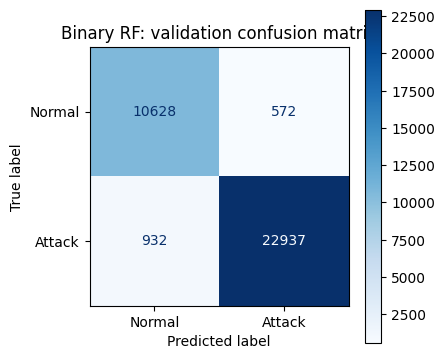

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    yb_val, pred_bin, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
ax.set_title("Binary RF: validation confusion matrix")
plt.tight_layout()
plt.show()

### Optional: tune the alert threshold

The default threshold is 0.5. Raising it gives fewer false alarms but misses more attacks. Pick the trade-off that suits your dashboard.

In [6]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (proba_bin >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yb_val, p, labels=[0, 1]).ravel()
    rows.append({
        "threshold": t,
        "precision": precision_score(yb_val, p, zero_division=0),
        "recall": recall_score(yb_val, p),
        "f1": f1_score(yb_val, p),
        "false_pos_rate": fp_ / (fp_ + tn_),
    })
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,false_pos_rate
0,0.3,0.9557,0.9871,0.9712,0.0975
1,0.4,0.9669,0.9754,0.9711,0.0712
2,0.5,0.9757,0.9610,0.9683,0.0511
3,0.6,0.9835,0.9447,0.9637,0.0338
4,0.7,0.9899,0.9250,0.9563,0.0202
5,0.8,0.9945,0.8977,0.9436,0.0106
6,0.9,0.9980,0.8504,0.9183,0.0037


## 5. Multiclass Random Forest (7 classes)

In [7]:
t0 = time.time()
rf_multi = RandomForestClassifier(**RF_PARAMS).fit(X_train, ym_train)
print(f"trained in {time.time() - t0:.1f}s")

pred_multi = rf_multi.predict(X_val)
print(classification_report(
    ym_val, pred_multi, labels=list(range(len(class_names))),
    target_names=class_names, digits=4, zero_division=0))
print("macro F1:   %.4f" % f1_score(ym_val, pred_multi, average="macro"))
print("weighted F1: %.4f" % f1_score(ym_val, pred_multi, average="weighted"))

trained in 8.7s
                precision    recall  f1-score   support

        Normal     0.9571    0.9169    0.9366     11200
           DoS     0.0486    0.0656    0.0558      2453
Reconnaissance     0.8296    0.7794    0.8037      2099
       Fuzzers     0.7516    0.7864    0.7686      3637
      Exploits     0.7509    0.5391    0.6276      6678
       Generic     0.9989    0.9808    0.9897      8000
         Other     0.1281    0.3323    0.1849      1002

      accuracy                         0.7615     35069
     macro avg     0.6378    0.6286    0.6239     35069
  weighted avg     0.8112    0.7615    0.7814     35069

macro F1:   0.6239
weighted F1: 0.7814


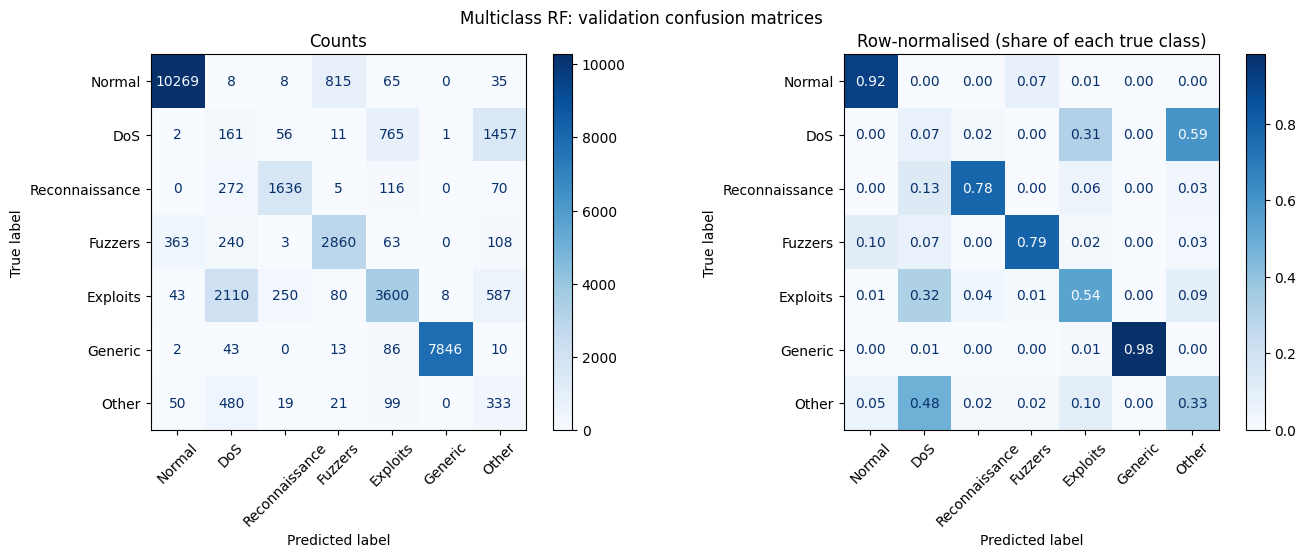

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
labels = list(range(len(class_names)))
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
axes[1].set_title("Row-normalised (share of each true class)")
plt.suptitle("Multiclass RF: validation confusion matrices")
plt.tight_layout()
plt.show()

## 5b. Detection rate by attack type

The confusion matrix mixes up two different questions: was the flow flagged as an attack at all, and was it given the right attack type? This table answers the first one. For the Normal row it is the false alarm rate.

In [9]:
flagged = pred_multi != 0          # class 0 is Normal
rows = []
for i, name in enumerate(class_names):
    m = ym_val == i
    rows.append({"true class": name, "flows": int(m.sum()),
                 "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                 "correct type (%)": round(100 * (pred_multi[m] == i).mean(), 2)})
pd.DataFrame(rows)

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,8.31,91.69
1,DoS,2453,99.92,6.56
2,Reconnaissance,2099,100.00,77.94
3,Fuzzers,3637,90.02,78.64
4,Exploits,6678,99.36,53.91
5,Generic,8000,99.98,98.08
6,Other,1002,95.01,33.23


## 6. Feature importance

Shows which features the forest relied on most. Useful for the explainability part of your project.

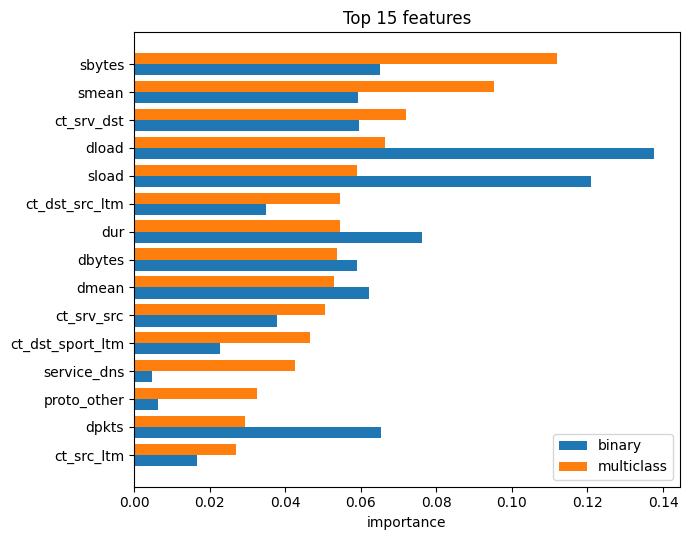

In [10]:
imp = (pd.DataFrame({
            "feature": feature_names,
            "binary": rf_bin.feature_importances_,
            "multiclass": rf_multi.feature_importances_})
       .sort_values("multiclass", ascending=False))

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
y = np.arange(len(top))
ax.barh(y - 0.2, top["binary"], height=0.4, label="binary")
ax.barh(y + 0.2, top["multiclass"], height=0.4, label="multiclass")
ax.set_yticks(y)
ax.set_yticklabels(top["feature"])
ax.set_xlabel("importance")
ax.set_title("Top 15 features")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Summary table (keep these numbers to compare against the MLP)

In [11]:
summary = pd.DataFrame([
    {"model": "RF binary",
     "precision": precision_score(yb_val, pred_bin),
     "recall": recall_score(yb_val, pred_bin),
     "f1": f1_score(yb_val, pred_bin),
     "false_pos_rate": fpr},
    {"model": "RF multiclass (macro)",
     "precision": precision_score(ym_val, pred_multi, average="macro", zero_division=0),
     "recall": recall_score(ym_val, pred_multi, average="macro", zero_division=0),
     "f1": f1_score(ym_val, pred_multi, average="macro"),
     "false_pos_rate": np.nan},
]).round(4)
summary

,model,precision,recall,f1,false_pos_rate
0,RF binary,0.9757,0.9610,0.9683,0.0511
1,RF multiclass (macro),0.6378,0.6286,0.6239,NaN


## 8. Save the models

Random Forests can be large, so they are compressed. The binary model is what the FastAPI backend will load first.

In [12]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

joblib.dump(rf_bin, mdir / "rf_binary.joblib", compress=3)
joblib.dump(rf_multi, mdir / "rf_multiclass.joblib", compress=3)
imp.to_csv(mdir / "rf_feature_importance.csv", index=False)
summary.to_csv(mdir / "rf_validation_summary.csv", index=False)

for f in sorted(mdir.glob("rf_*")):
    print(f"{f.name:32s} {f.stat().st_size / 1e6:8.1f} MB")

rf_binary.joblib                     37.2 MB
rf_feature_importance.csv             0.0 MB
rf_multiclass.joblib                 99.5 MB
rf_validation_summary.csv             0.0 MB


## 9. How to use the saved model later (live pipeline)

```python
rf = joblib.load("models/rf_binary.joblib")
X = transform_with_artifacts(build_model_frame(flows_df))   # from the preprocessing notebook
alert = rf.predict_proba(X)[:, 1] >= 0.5
```